# Tugas 2 - Klasifikasi Diabetes dengan Naive Bayes dan Logistic Regression

| Nama | NRP |
|------|-----|
| Fahmi Alfayadh| 5054251015|

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Pima Indians Diabetes Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/jamaltariqcheema/pima-indians-diabetes-dataset

Tujuan utama dari tugas ini adalah membangun model Naive Bayes dan Logistic Regression untuk mengklasifikasikan apakah seorang pasien menderita diabetes atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model.
3. Eksperimen Model
   - Bangun model Gaussian Naive Bayes dan Logistic Regression.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil kedua model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [19]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, recall_score, classification_report, confusion_matrix


In [20]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv('dataset/diabetes.csv')
print("Jumlah baris dan kolom:", df.shape)
print("Tipe data:")
print(df.dtypes)
print()
print("Statistik deskriptif:")
print(df.describe())
print()
print("Jumlah missing value:")
print(df.isnull().sum())

df.head()


Jumlah baris dan kolom: (768, 9)
Tipe data:
Pregnancies                   int64
Glucose                       int64
BloodPressure               float64
SkinThickness                 int64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Statistik deskriptif:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  121.677083      72.389323      29.089844  141.753906   
std       3.369578   30.464161      12.106039       8.890820   89.100847   
min       0.000000   44.000000      24.000000       7.000000   14.000000   
25%       1.000000   99.750000      64.000000      25.000000  102.500000   
50%       3.000000  117.000000      72.000000      28.000000  102.500000   
75%       6.000000  140.250000      80.000000      32.000000  1

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


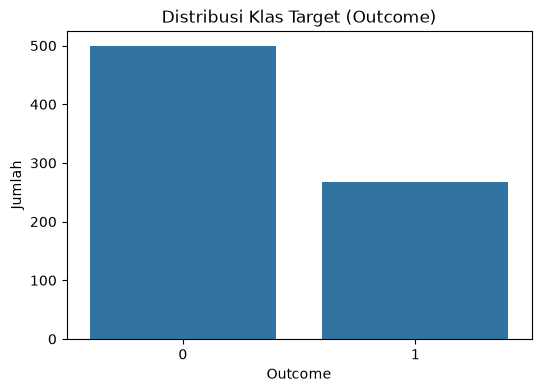

Distribusi kelas target (Outcome):
Outcome
0    65.104167
1    34.895833
Name: count, dtype: float64


In [21]:
# Tampilkan distribusi kelas target (Outcome) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

plt.figure(figsize=(6, 4))
sns.countplot(x='Outcome', data=df)
plt.title('Distribusi Klas Target (Outcome)')
plt.xlabel('Outcome')
plt.ylabel('Jumlah')
plt.show()

print("Distribusi kelas target (Outcome):")
print(df['Outcome'].value_counts() / len(df) * 100)

bias ke 0, 65%

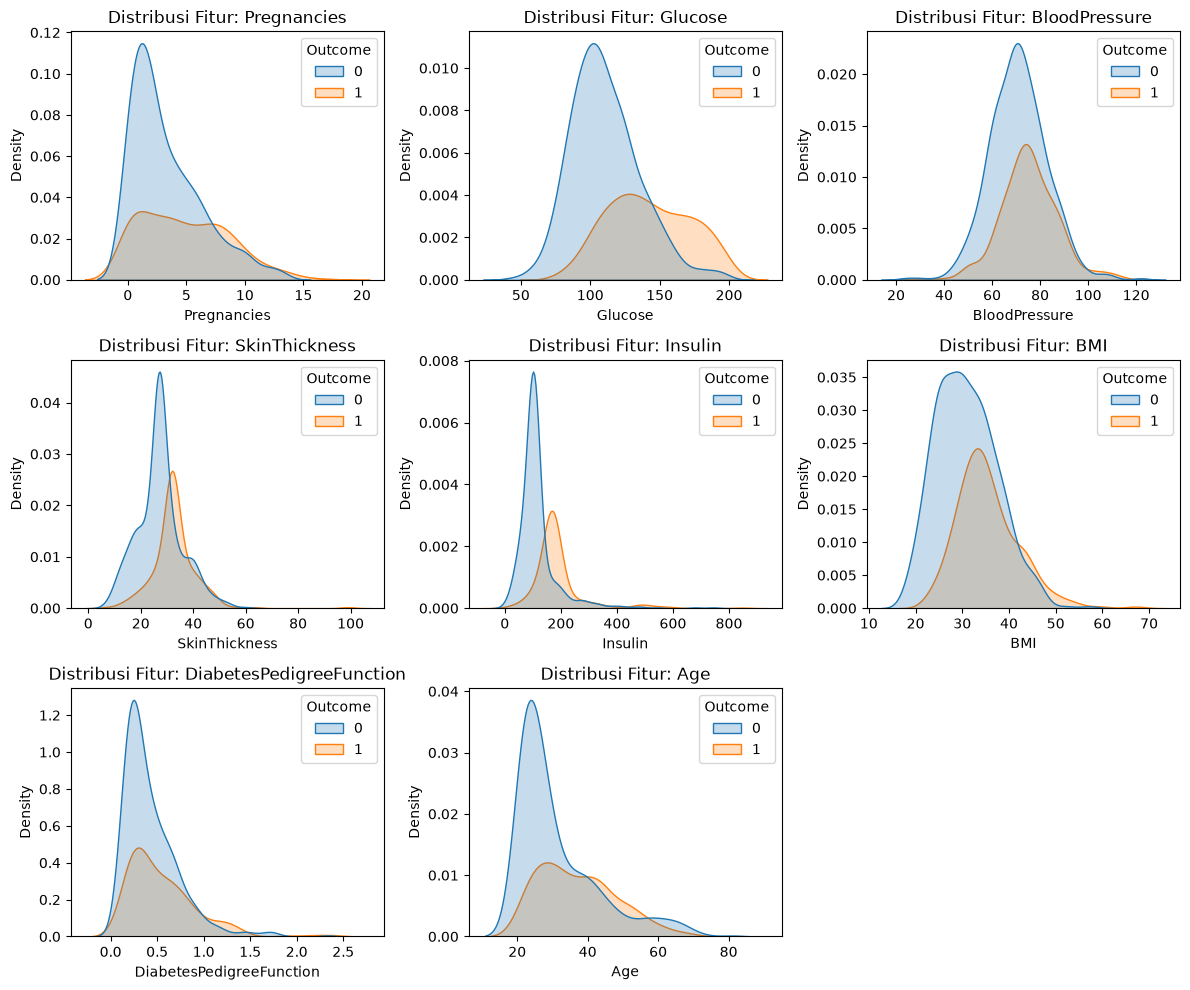

In [39]:
# Tampilkan distribusi setiap fitur menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Outcome.
plt.figure(figsize=(12, 10))
for column in df.columns:
    if column != 'Outcome':
        plt.subplot(3, 3, list(df.columns).index(column) + 1)
        sns.kdeplot(data=df, x=column, hue='Outcome', fill=True)
        plt.title(f'Distribusi Fitur: {column}')
plt.tight_layout()

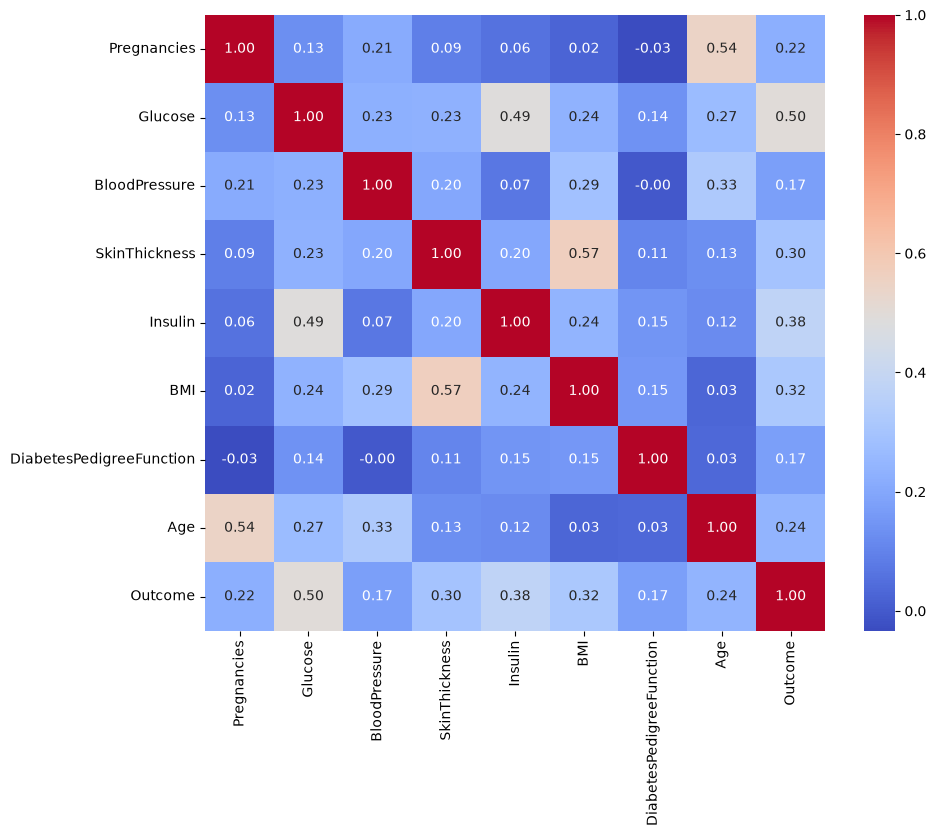

In [23]:
# Tampilkan heatmap korelasi antar fitur.
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [24]:
# Beberapa kolom seperti Glucose, BloodPressure, SkinThickness, Insulin, dan BMI memiliki nilai 0 yang secara medis tidak mungkin.
# Identifikasi kolom-kolom tersebut dan hitung jumlah nilai 0 pada masing-masing kolom.

zero_columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for column in zero_columns:
    print(f"Jumlah nilai 0 pada kolom '{column}': {(df[column] == 0).sum()}")


Jumlah nilai 0 pada kolom 'Glucose': 0
Jumlah nilai 0 pada kolom 'BloodPressure': 0
Jumlah nilai 0 pada kolom 'SkinThickness': 0
Jumlah nilai 0 pada kolom 'Insulin': 0
Jumlah nilai 0 pada kolom 'BMI': 0


In [25]:
# Tangani nilai 0 tersebut dengan strategi yang sesuai (misalnya imputasi dengan median atau mean).
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.

zero_columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
# Ganti nilai 0 dengan NaN terlebih dahulu agar tidak membiaskan statistik data
df[zero_columns] = df[zero_columns].replace(0, np.nan)

print("Jumlah missing value (NaN) setelah mengganti nilai 0:")
print(df[zero_columns].isnull().sum()) 


Jumlah missing value (NaN) setelah mengganti nilai 0:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [26]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.

X = df.drop(columns=['Outcome'])
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Imputasi nilai NaN dengan median dari train set agar tidak terjadi data leakage
for column in zero_columns:
    median_val = X_train[column].median()
    X_train[column] = X_train[column].fillna(median_val)
    X_test[column] = X_test[column].fillna(median_val)

print("Jumlah missing value pada X_train setelah imputasi:")
print(X_train.isnull().sum())
print("\nJumlah missing value pada X_test setelah imputasi:")
print(X_test.isnull().sum())


Jumlah missing value pada X_train setelah imputasi:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64

Jumlah missing value pada X_test setelah imputasi:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


In [27]:
# Lakukan feature scaling menggunakan StandardScaler.
# Fit hanya pada train set, kemudian transform pada train set dan test set.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 3. Eksperimen Model

## 3.1 Gaussian Naive Bayes

Gunakan GaussianNB karena semua fitur pada dataset ini bersifat numerik kontinu.

In [28]:
# Inisialisasi dan latih model Gaussian Naive Bayes menggunakan train set.
from sklearn.naive_bayes import GaussianNB

gaussiannb = GaussianNB()
gaussiannb.fit(X_train_scaled, y_train)


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[400.,214.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.65,0.35]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 8)","[[-0.15,-0.38,-0.14,...,-0.24,-0.12,-0.18], [ 0.28, 0.71, 0.26,..., 0.45, 0.23, 0.33]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 8)","[[0.81,0.61,0.98,...,0.86,0.85,0.96], [1.23,0.97,0.94,...,0.94,1.2 ,0.91]]"


In [14]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
from sklearn.metrics import recall_score

recall_scores = {}

y_pred_gaussian = gaussiannb.predict(X_test_scaled)
recall = recall_score(y_test, y_pred_gaussian)
recall_scores['GaussianNB (Default)'] = recall
print(f"Recall (Kelas 1): {recall:.4f}")

print(classification_report(y_test, y_pred_gaussian))
print(confusion_matrix(y_test, y_pred_gaussian))

y_pred_proba_gaussian = gaussiannb.predict_proba(X_test_scaled)[:, 1]

custom_threshold = 0.35
y_pred_gaussian_custom = (y_pred_proba_gaussian >= custom_threshold).astype(int)

# 4. Evaluasi menggunakan hasil prediksi threshold baru
recall_custom = recall_score(y_test, y_pred_gaussian_custom)
recall_scores['GaussianNB (Threshold 0.35)'] = recall_custom

print(f"\nThreshold: {custom_threshold}")
print(f"Recall (Kelas 1): {recall_custom:.4f}")
print("\nClassification Report (Custom Threshold):")
print(classification_report(y_test, y_pred_gaussian_custom))
print("Confusion Matrix (Custom Threshold):")
print(confusion_matrix(y_test, y_pred_gaussian_custom))

# 5. Simpan ke DataFrame
hasil_prediksi_gaussian = pd.DataFrame({
    'y_true': y_test,
    'y_pred_default': y_pred_gaussian,
    'y_pred_custom': y_pred_gaussian_custom,
    'y_pred_proba': y_pred_proba_gaussian
})


Recall (Kelas 1): 0.6481
              precision    recall  f1-score   support

           0       0.80      0.77      0.79       100
           1       0.60      0.65      0.62        54

    accuracy                           0.73       154
   macro avg       0.70      0.71      0.71       154
weighted avg       0.73      0.73      0.73       154

[[77 23]
 [19 35]]

Threshold: 0.35
Recall (Kelas 1): 0.6852

Classification Report (Custom Threshold):
              precision    recall  f1-score   support

           0       0.81      0.72      0.76       100
           1       0.57      0.69      0.62        54

    accuracy                           0.71       154
   macro avg       0.69      0.70      0.69       154
weighted avg       0.72      0.71      0.71       154

Confusion Matrix (Custom Threshold):
[[72 28]
 [17 37]]


## 3.2 Logistic Regression

In [15]:
# Inisialisasi dan latih model Logistic Regression menggunakan train set.
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
logreg.fit(X_train_scaled, y_train)


In [16]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
y_pred_logreg = logreg.predict(X_test_scaled)
recall = recall_score(y_test, y_pred_logreg)
recall_scores['LogisticRegression (Default)'] = recall
print(f"Recall (Kelas 1): {recall:.4f}")

print(classification_report(y_test, y_pred_logreg))
print(confusion_matrix(y_test, y_pred_logreg))

y_pred_proba_logreg = logreg.predict_proba(X_test_scaled)[:, 1]

custom_threshold = 0.35
y_pred_logreg_custom = (y_pred_proba_logreg >= custom_threshold).astype(int)

# 4. Evaluasi menggunakan hasil prediksi threshold baru
recall_logreg_custom = recall_score(y_test, y_pred_logreg_custom)
recall_scores['LogisticRegression (Threshold 0.35)'] = recall_logreg_custom

print(f"\nThreshold: {custom_threshold}")
print(f"Recall (Kelas 1): {recall_logreg_custom:.4f}")
print("\nClassification Report (Custom Threshold):")
print(classification_report(y_test, y_pred_logreg_custom))
print("Confusion Matrix (Custom Threshold):")
print(confusion_matrix(y_test, y_pred_logreg_custom))

# 5. Simpan ke DataFrame
hasil_prediksi_logreg = pd.DataFrame({
    'y_true': y_test,
    'y_pred_default': y_pred_logreg,
    'y_pred_custom': y_pred_logreg_custom,
    'y_pred_proba': y_pred_proba_logreg
})
hasil_prediksi_logreg.to_csv('prediksi_logreg.csv', index=False)


Recall (Kelas 1): 0.7778
              precision    recall  f1-score   support

           0       0.86      0.73      0.79       100
           1       0.61      0.78      0.68        54

    accuracy                           0.75       154
   macro avg       0.73      0.75      0.74       154
weighted avg       0.77      0.75      0.75       154

[[73 27]
 [12 42]]

Threshold: 0.35
Recall (Kelas 1): 0.9259

Classification Report (Custom Threshold):
              precision    recall  f1-score   support

           0       0.94      0.61      0.74       100
           1       0.56      0.93      0.70        54

    accuracy                           0.72       154
   macro avg       0.75      0.77      0.72       154
weighted avg       0.81      0.72      0.73       154

Confusion Matrix (Custom Threshold):
[[61 39]
 [ 4 50]]


# 4. Evaluasi Model

========= Evaluasi Recall Model (Kelas 1 - Diabetes) =========
GaussianNB (Default): 0.6481
GaussianNB (Threshold 0.35): 0.6852
LogisticRegression (Default): 0.7778
LogisticRegression (Threshold 0.35): 0.9259

========= Perbandingan Metrik Evaluasi (Default Threshold 0.5) =========
GaussianNB (Default 0.5):
              precision    recall  f1-score   support

           0       0.80      0.77      0.79       100
           1       0.60      0.65      0.62        54

    accuracy                           0.73       154
   macro avg       0.70      0.71      0.71       154
weighted avg       0.73      0.73      0.73       154

LogisticRegression (Default 0.5):
              precision    recall  f1-score   support

           0       0.86      0.73      0.79       100
           1       0.61      0.78      0.68        54

    accuracy                           0.75       154
   macro avg       0.73      0.75      0.74       154
weighted avg       0.77      0.75      0.75       154


==

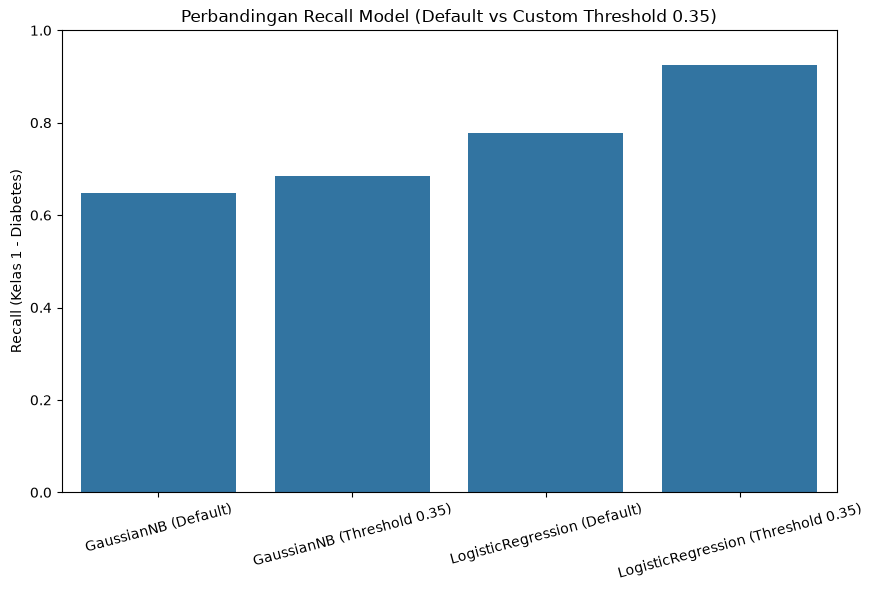

In [17]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
print("========= Evaluasi Recall Model (Kelas 1 - Diabetes) =========")
for model, rec in recall_scores.items():
    print(f"{model}: {rec:.4f}")

print("\n========= Perbandingan Metrik Evaluasi (Default Threshold 0.5) =========")
print("GaussianNB (Default 0.5):")
print(classification_report(y_test, y_pred_gaussian))

print("LogisticRegression (Default 0.5):")
print(classification_report(y_test, y_pred_logreg))

print("\n========= Perbandingan Metrik Evaluasi (Custom Threshold 0.35) =========")
print("GaussianNB (Threshold 0.35):")
print(classification_report(y_test, y_pred_gaussian_custom))

print("LogisticRegression (Threshold 0.35):")
print(classification_report(y_test, y_pred_logreg_custom))

plt.figure(figsize=(10, 6))
sns.barplot(x=list(recall_scores.keys()), y=list(recall_scores.values()))
plt.title('Perbandingan Recall Model (Default vs Custom Threshold 0.35)')
plt.ylabel('Recall (Kelas 1 - Diabetes)')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()



========= Confusion Matrix GaussianNB (Default 0.5) =========


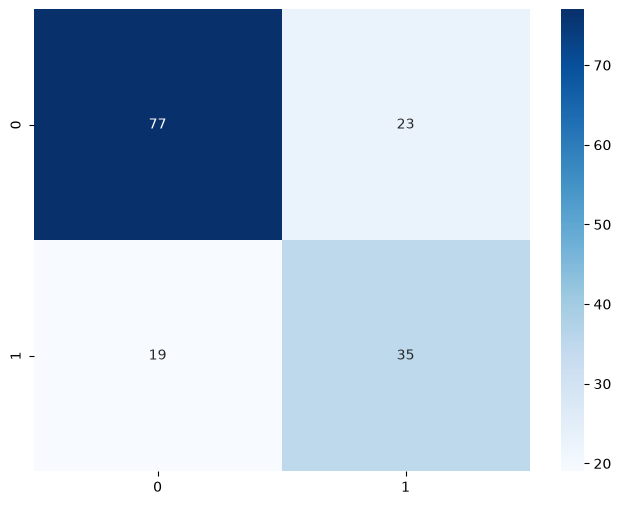


========= Confusion Matrix GaussianNB (Threshold 0.35) =========


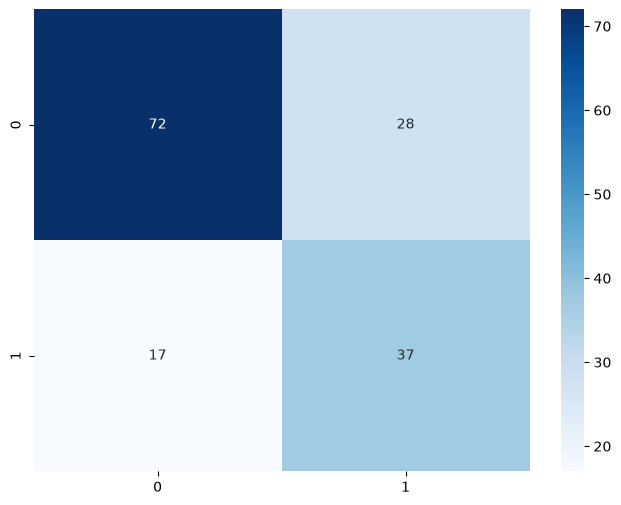


========= Confusion Matrix LogisticRegression (Default 0.5) =========


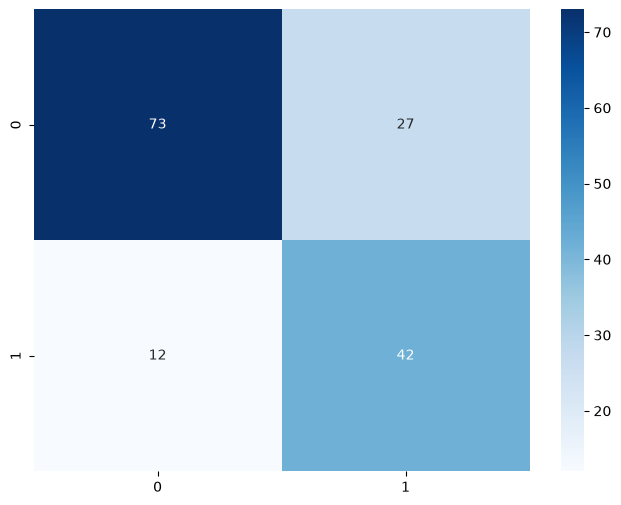


========= Confusion Matrix LogisticRegression (Threshold 0.35) =========


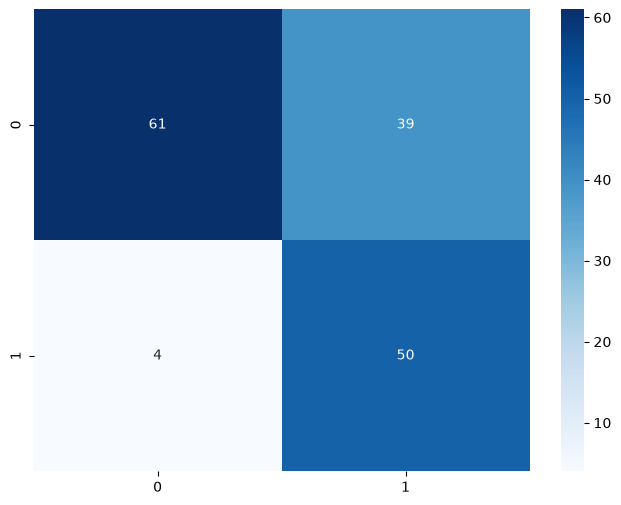

In [18]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
print("\n========= Confusion Matrix GaussianNB (Default 0.5) =========")
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_gaussian), annot=True, fmt='d', cmap='Blues')
plt.show()

print("\n========= Confusion Matrix GaussianNB (Threshold 0.35) =========")
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_gaussian_custom), annot=True, fmt='d', cmap='Blues')
plt.show()

print("\n========= Confusion Matrix LogisticRegression (Default 0.5) =========")
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_logreg), annot=True, fmt='d', cmap='Blues')
plt.show()

print("\n========= Confusion Matrix LogisticRegression (Threshold 0.35) =========")
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_logreg_custom), annot=True, fmt='d', cmap='Blues')
plt.show()


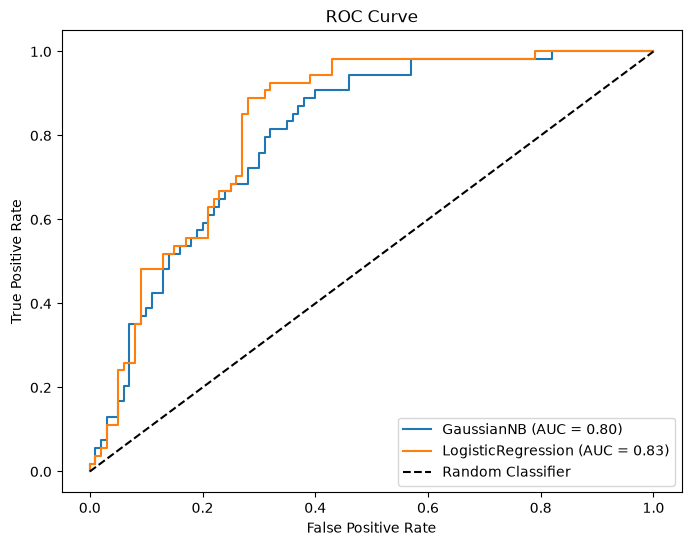

In [57]:
# Tampilkan ROC Curve kedua model dalam satu plot beserta nilai AUC masing-masing.
from sklearn.metrics import roc_auc_score, roc_curve

plt.figure(figsize=(8, 6))

# GaussianNB
y_pred_proba = gaussiannb.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
auc = roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr, tpr, label=f'GaussianNB (AUC = {auc:.2f})')

# LogisticRegression
y_pred_proba = logreg.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
auc = roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr, tpr, label=f'LogisticRegression (AUC = {auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


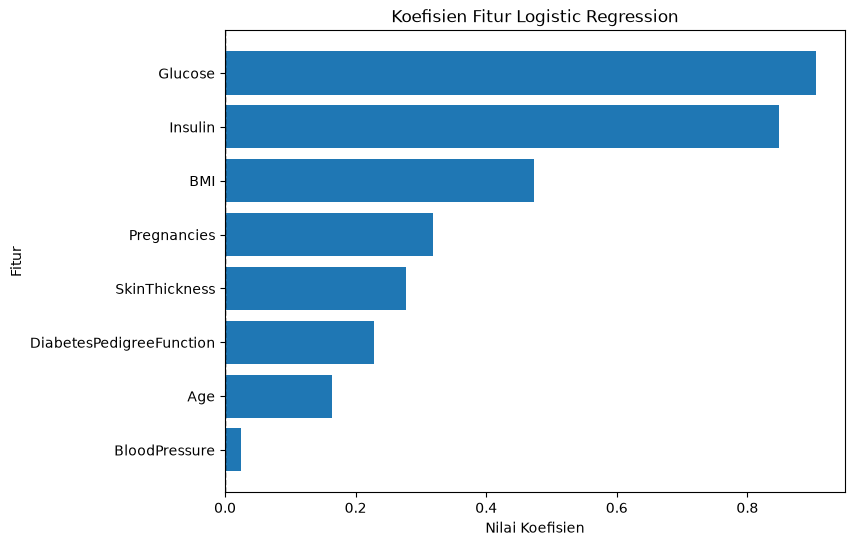


========= Nilai Koefisien Fitur Logistic Regression =========
BloodPressure: 0.0237
Age: 0.1645
DiabetesPedigreeFunction: 0.2279
SkinThickness: 0.2777
Pregnancies: 0.3186
BMI: 0.4739
Insulin: 0.8491
Glucose: 0.9044


In [ ]:
# koefisien setiap fitur pdada logreg.

coef_df = pd.DataFrame({
    'Fitur': X.columns,
    'Koefisien': logreg.coef_[0]
}).sort_values(by='Koefisien', ascending=True)

plt.figure(figsize=(8, 6))
plt.barh(coef_df['Fitur'], coef_df['Koefisien'])
plt.xlabel('Nilai Koefisien')
plt.ylabel('Fitur')
plt.title('Koefisien Fitur Logistic Regression')
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.show()

print("\n========= Nilai Koefisien Fitur Logistic Regression =========")
for idx, row in coef_df.iterrows():
    print(f"{row['Fitur']}: {row['Koefisien']:.4f}")


# 5. Analisis

### 5.1 Perbandingan Kinerja Model (Fokus pada Metrik Recall)

Tabel evaluasi data uji (154 sampel) setelah penerapan `class_weight='balanced'` pada Logistic Regression:

| Model | Threshold | Recall (1) | FN | TP | Precision (1) | F1-Score (1) | Akurasi | ROC-AUC |
|---|---|---|---|---|---|---|---|---|
| **GaussianNB** | 0.5 (Default) | 64.81% | 19 | 35 | 0.60 | 0.62 | 72.73% | 0.80 |
| **GaussianNB** | 0.35 (Custom) | 68.52% | 17 | 37 | 0.57 | 0.62 | 71.43% | 0.80 |
| **Logistic Regression (Balanced)** | 0.5 (Default) | 77.78% | 12 | 42 | 0.61 | 0.68 | 74.68% | 0.83 |
| **Logistic Regression (Balanced)** | 0.35 (Custom) | 92.59% | 4 | 50 | 0.56 | 0.70 | 72.08% | 0.83 |

*Catatan: Kelas 0 = non-diabetes (100 sampel), Kelas 1 = diabetes (54 sampel).*

### 5.2 Dampak `class_weight='balanced'` dan Custom Threshold

1. **Efek `class_weight='balanced'` pada Threshold Default (0.5)**
   - Pembobotan kelas berhasil mengatasi ketidakseimbangan data (65% vs 35%).
   - Recall Logistic Regression melonjak signifikan dari 55.56% menjadi **77.78%** (+22.22%), memangkas False Negative dari 24 menjadi 12 kasus, sekaligus mencatat akurasi tertinggi sebesar 74.68%.

2. **Efek Penurunan Threshold ke 0.35**
   - Penurunan threshold ke 0.35 mendorong Recall Logistic Regression mencapai **92.59%** (50 dari 54 pasien diabetes berhasil terdeteksi).
   - False Negative ditekan hingga tersisa hanya 4 kasus, dengan F1-Score mencapai angka tertinggi (0.70).
   - Sebagai trade-off klinis, False Positive bertambah menjadi 39 kasus, yang sangat wajar pada tahap skrining medis demi menghindari pasien berisiko terlewat.

3. **Perbandingan dengan GaussianNB**
   - GaussianNB tidak memiliki mekanisme pembobotan kelas bawaan, sehingga Recall berada di angka 64.81% (default) dan 68.52% (threshold 0.35). Logistic Regression dengan balanced weighting jauh lebih unggul dalam mendeteksi kelas minoritas.

### 5.3 Analisis Koefisien Fitur (Logistic Regression)

- Fitur `Glucose` (+0.9044) dan `Insulin` (+0.8491) menjadi dua prediktor positif paling dominan terhadap risiko diabetes, diikuti oleh `BMI` (+0.4739) dan `Pregnancies` (+0.3186).
- Fitur `BloodPressure` (+0.0237) memiliki koefisien paling kecil mendekati nol, menunjukkan pengaruh minimal terhadap klasifikasi.

# 6. Kesimpulan

### 6. Kesimpulan

1. Penerapan `class_weight='balanced'` terbukti sangat efektif mengatasi isu imbalanced data, menaikkan Recall Logistic Regression dari 55.56% menjadi 77.78% pada threshold default 0.5.
2. Kombinasi `class_weight='balanced'` dengan custom threshold 0.35 menghasilkan performa skrining terbaik dengan Recall mencapai **92.59%** dan meminimalkan False Negative hingga tersisa 4 kasus.
3. Logistic Regression terbukti lebih unggul dibanding GaussianNB pada dataset ini, baik dari segi Recall (92.59% vs 68.52%), F1-Score (0.70 vs 0.62), maupun ROC-AUC (0.83 vs 0.80).
4. `Glucose`, `Insulin`, dan `BMI` merupakan tiga indikator klinis paling berpengaruh dalam memprediksi risiko diabetes pada model.